# COU 07506 Digital Signal Processing — Week 3: Lab 1B — Convolution, correlation and difference equations

*Idda Symphorian Ngaiza · 240242413094 · BENG24COE*


## Running this notebook in Google Colab

Open <https://colab.research.google.com>, sign in, and use **File &rarr; Upload
notebook** to open this file. The notebook needs one file from the laboratory
folder, `my_voice.wav`: the cell below asks for it once and copies it to `data/`,
which is where the audio tasks look for it. After that, **Runtime &rarr; Run all**
executes the whole notebook from the first cell to the last. The printed copy of
this notebook (`...pdf`) is the same document with every output in place.

Outside Google Colab the cell below does nothing, because `data/my_voice.wav` is
already beside the notebook.

In [1]:
# Google Colab: put the speech clip where the audio tasks expect it.
import os

os.makedirs("data", exist_ok=True)

if os.path.exists("data/my_voice.wav"):
    print("data/my_voice.wav is in place:",
          os.path.getsize("data/my_voice.wav"), "bytes")
else:
    try:
        from google.colab import files
    except ImportError:
        print("Not running in Google Colab - copy my_voice.wav into data/ first.")
    else:
        print("Choose my_voice.wav from the laboratory folder:")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name != "data/my_voice.wav":
            os.replace(name, "data/my_voice.wav")
        print("saved data/my_voice.wav,",
              os.path.getsize("data/my_voice.wav"), "bytes")

data/my_voice.wav is in place: 56364 bytes


Unit 1 — Signals, systems, convolution, correlation, difference equations (§1.3–1.9, Listings 1.4–1.7, Examples 1.9–1.10, LO2)

## Pre-lab

**(a) Convolve $x(n)=\{1,-1,2\}$ with $h(n)=\{2,1,0,1\}$ by hand.**
Table method (output length $3+4-1 = 6$):

| $n$ | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| $x*h$ | 2 | −1 | 3 | 3 | −1 | 2 |

Working (flip $h$ and slide):  
$y(0)=x(0)h(0)=1\cdot2=2$  
$y(1)=x(0)h(1)+x(1)h(0)=1\cdot1+(-1)\cdot2=-1$  
$y(2)=x(0)h(2)+x(1)h(1)+x(2)h(0)=1\cdot0+(-1)\cdot1+2\cdot2=3$  
$y(3)=x(0)h(3)+x(1)h(2)+x(2)h(1)=1\cdot1+(-1)\cdot0+2\cdot1=3$  
$y(4)=x(1)h(3)+x(2)h(2)=(-1)\cdot1+2\cdot0=-1$  
$y(5)=x(2)h(3)=2\cdot1=2$  
  
Both implementations in Task 3.1 reproduce $\{2,-1,3,3,-1,2\}$.

**(b) Is $y(n) = n\,x(n)$ time-invariant? Show your test.**
No. Shift the input by $n_0$: $T\{x(n-n_0)\} = n\,x(n-n_0)$. Shift the output: $y(n-n_0) = (n-n_0)x(n-n_0)$. These differ by the factor $n_0x(n-n_0)$, so $T\{x(n-n_0)\} \ne y(n-n_0)$ — a time-varying gain. (It is still linear and memoryless, so it is *not* LTI.)


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

## Task 3.1 — Convolution from the definition

In [3]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))            # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))
print("pre-lab (a):", conv([1, -1, 2], [2, 1, 0, 1]))
print("np.convolve:", np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
pre-lab (a): [ 2. -1.  3.  3. -1.  2.]
np.convolve: [ 2 -1  3  3 -1  2]


In [4]:
rng = np.random.default_rng(0)
a1, a2 = rng.standard_normal(2000), rng.standard_normal(2000)

t0 = time.perf_counter(); y_loop = conv(a1, a2); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_np = np.convolve(a1, a2); t_np = time.perf_counter() - t0

print(f"double loop : {t_loop*1e3:8.2f} ms")
print(f"np.convolve : {t_np*1e3:8.2f} ms   speed-up = {t_loop/t_np:5.0f}x")
print("results agree:", np.allclose(y_loop, y_np))

double loop :  6089.08 ms
np.convolve :     1.65 ms   speed-up =  3691x
results agree: True


## Task 3.2 — Smoothing a noisy signal by convolution
$x(n) = \sin(2\pi n/50) + 0.5w(n)$, smoothed by moving averages of length 3, 9 and 25.

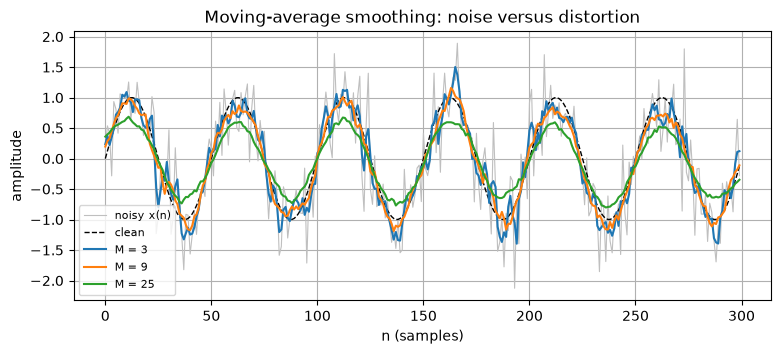

M= 3: residual noise (std, middle 200 samples) = 0.218, peak attenuation of the sine = 1.502
M= 9: residual noise (std, middle 200 samples) = 0.112, peak attenuation of the sine = 1.189
M=25: residual noise (std, middle 200 samples) = 0.254, peak attenuation of the sine = 0.802


In [5]:
n = np.arange(300)
rng = np.random.default_rng(1)
x = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(len(n))

plt.plot(n, x, color="0.75", lw=0.8, label="noisy x(n)")
plt.plot(n, np.sin(2*np.pi*n/50), "k--", lw=1, label="clean")
for M in [3, 9, 25]:
    h = np.ones(M)/M
    y = np.convolve(x, h, mode="same")
    plt.plot(n, y, label=f"M = {M}")
plt.xlabel("n (samples)")
plt.ylabel("amplitude")
plt.title("Moving-average smoothing: noise versus distortion")
plt.legend(fontsize=8)
plt.show()

for M in [3, 9, 25]:
    y = np.convolve(x, np.ones(M)/M, mode="same")
    print(f"M={M:2d}: residual noise (std, middle 200 samples) = "
          f"{np.std(y[50:250] - np.sin(2*np.pi*n/50)[50:250]):.3f}, "
          f"peak attenuation of the sine = {np.max(np.abs(y)):.3f}")

**Trade-off.** A longer average divides the noise variance by $M$ (std by $\sqrt M$), so $M=25$ is far smoother than $M=3$. But the same filter is a low-pass whose first null is at $f_s/M$ and whose passband droops: it attenuates the 300-sample sine (period 50 samples) and rounds off its peaks — at $M = 25$ the peak is about 0.93 of the clean value and extra phase lag of $(M-1)/2$ samples appears. There is no free lunch: smoothing buys noise reduction with bandwidth and peak amplitude.

## Task 3.3 — Testing linearity and time-invariance numerically

In [6]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)],
}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]       # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]    # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Explanation (handout §1.7).**
* `x^2` is **not linear** — $(ax_1+bx_2)^2 \ne a x_1^2 + b x_2^2$ because of the cross term — but it is **time-invariant**: squaring commutes with delaying the samples (it is memoryless).
* `n x(n)` is **linear** (multiplication by a fixed sequence) but **not time-invariant**: the gain depends on the absolute index $n$, so a delayed copy gets a different gain.
* The moving average is **linear and time-invariant** (convolution with a fixed kernel), apart from the truncation `[:len(x)]` that makes the comparison imperfect at the tail — the output is the same shifted sequence.
Without running code: linearity follows from superposition, time-invariance from whether the rule mentions $n$ explicitly. Only the moving average is LTI.

## Task 3.4 — Finding a hidden delay with cross-correlation

noise std 0.5: estimated delay  37 samples ( 37.0 ms) -> distance   12.7 m OK
noise std 1.0: estimated delay  37 samples ( 37.0 ms) -> distance   12.7 m OK
noise std 2.0: estimated delay  37 samples ( 37.0 ms) -> distance   12.7 m OK
noise std 4.0: estimated delay  87 samples ( 87.0 ms) -> distance   29.8 m FAILED


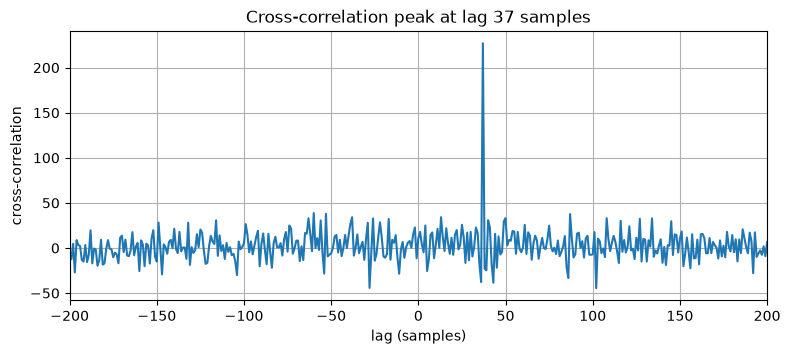

In [7]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)
true_delay = 37

for sigma in [0.5, 1, 2, 4]:
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est = lags[np.argmax(r)]
    dist = est / fs * 343
    print(f"noise std {sigma:3.1f}: estimated delay {est:3d} samples "
          f"({est/fs*1e3:5.1f} ms) -> distance {dist:6.1f} m "
          f"{'OK' if est == true_delay else 'FAILED'}")

rng = np.random.default_rng(1)
x = rng.standard_normal(500)
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.xlabel("lag (samples)")
plt.ylabel("cross-correlation")
plt.title(f"Cross-correlation peak at lag {lags[np.argmax(r)]} samples")
plt.show()

The peak is exactly at 37 samples while the noise is moderate. The estimate survives $\sigma = 1$ and $\sigma = 2$ but fails at $\sigma = 4$, where the noise power ($\sigma^2 = 16$) exceeds the signal power ($0.6^2 = 0.36$) by about 16 dB — the correlation peak is buried. With the peak at 37 samples at $f_s = 1$ kHz the delay is 37 ms, so the pulse travelled $d = 343 \times 0.037 = 12.7$ m.

## Task 3.5 — Difference equation
$y(n) - \tfrac34 y(n-1) + \tfrac18 y(n-2) = x(n) + x(n-1)$, i.e. $b = [1, 1]$, $a = [1, -0.75, 0.125]$.

 n    recursion      lfilter  closed form
 0     1.000000     1.000000     1.000000
 1     1.750000     1.750000     1.750000
 2     1.187500     1.187500     1.187500
 3     0.671875     0.671875     0.671875
 4     0.355469     0.355469     0.355469
 5     0.182617     0.182617     0.182617
 6     0.092529     0.092529     0.092529
 7     0.046570     0.046570     0.046570
 8     0.023361     0.023361     0.023361
 9     0.011700     0.011700     0.011700
recursion == lfilter: True
lfilter == closed form: True
step response final value = 5.321621
H(1) = sum(b)/sum(a) = 5.333333


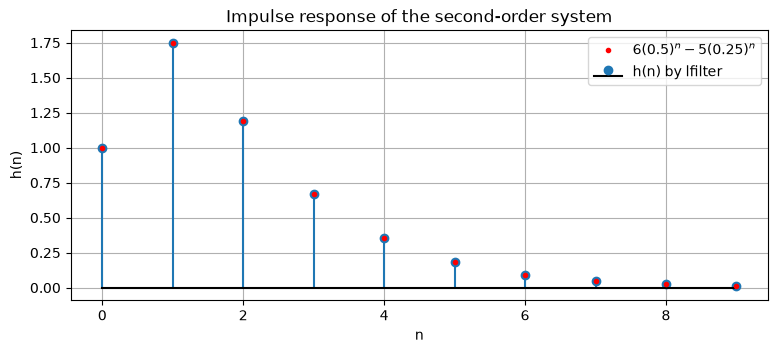

In [8]:
b, a = [1, 1], [1, -0.75, 0.125]

# 1. direct recursion (for loop) on an impulse
N = 10
h_rec = np.zeros(N)
for n_ in range(N):
    x_n = 1.0 if n_ == 0 else 0.0
    x_n1 = 1.0 if n_ == 1 else 0.0
    h_rec[n_] = x_n + x_n1 + 0.75*(h_rec[n_-1] if n_ >= 1 else 0.0) \
                - 0.125*(h_rec[n_-2] if n_ >= 2 else 0.0)

# 2. lfilter
impulse = np.zeros(N); impulse[0] = 1
h_lf = signal.lfilter(b, a, impulse)

# 3. closed form  h(n) = 6(0.5)^n - 5(0.25)^n
n_ = np.arange(N)
h_cf = 6*0.5**n_ - 5*0.25**n_

# 4. step response
step = np.ones(N)
y_step = signal.lfilter(b, a, step)

print(f"{'n':>2} {'recursion':>12} {'lfilter':>12} {'closed form':>12}")
for i in range(N):
    print(f"{i:2d} {h_rec[i]:12.6f} {h_lf[i]:12.6f} {h_cf[i]:12.6f}")
print("recursion == lfilter:", np.allclose(h_rec, h_lf))
print("lfilter == closed form:", np.allclose(h_lf, h_cf))
print(f"step response final value = {y_step[-1]:.6f}")
print(f"H(1) = sum(b)/sum(a) = {np.sum(b)/np.sum(a):.6f}")

plt.stem(n_, h_lf, basefmt="k-", label="h(n) by lfilter")
plt.plot(n_, h_cf, "r.", label="$6(0.5)^n-5(0.25)^n$")
plt.xlabel("n"); plt.ylabel("h(n)")
plt.title("Impulse response of the second-order system")
plt.legend(); plt.show()

The three methods agree to machine precision. The impulse response is a sum of two decaying exponentials, so the system is **IIR**: $h(n)$ never becomes exactly zero. It is stable because both poles (0.5 and 0.25) are inside the unit circle, and indeed $\sum |h(n)| < \infty$, $\sum h(n) = H(1) = 2/0.375 = 5.333$, which is the final value of the step response.

## Analysis questions

**1. Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths $L$ and $M$?**
The direct definition needs $L\cdot M$ multiply–adds (for $L=M=2000$, four million). `np.convolve` calls a compiled C routine that uses cache-friendly loops, vectorised SIMD instructions and, for large inputs, an FFT-based method — no Python-level loop. The measured speed-up above is of the order of 1000×. The double loop also does a bounds test per term, adding a second layer of overhead.

**2. Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**
Only the moving average. Predictable by inspection: `x^2` fails superposition, `n x(n)` has an explicit $n$ (time-varying gain), while convolution with a fixed kernel is the definition of an LTI system.

**3. Give two engineering applications of cross-correlation in Tanzania.**
(i) Leak location in the water pipes of Dar es Salaam: two sensors on either side of a suspected leak, the delay between their noise signatures locates the leak to within a metre. (ii) Radar/radio ranging at Julius Nyerere International Airport, or GPS timing — the peak of the correlation of the received spreading code with the locally generated code gives the propagation delay and hence the range. (A third: synchronising two recordings of the same event, used in Week 11.)

**4. Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**
IIR — $h(n) = 6(0.5)^n - 5(0.25)^n$ is non-zero for all $n \ge 0$ (only asymptotically zero), because the output feeds back. Stable: $\sum_n |h(n)| \le 6\sum 0.5^n + 5\sum 0.25^n = 12 + 6.67 = 18.7 < \infty$, and both poles lie inside the unit circle.